# Exploring horse2zebra

Before building any model, get to know the data.

**How to run:** use the `horse2zebra` conda kernel. Download the data first with
`python scripts/download_data.py` (from the repo root). 

In [1]:
from pathlib import Path
import json
import random

from PIL import Image          # import PIL before torch/matplotlib (see root README)
import numpy as np
import matplotlib.pyplot as plt

# Find the repo root
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "environment.yml").exists()), None)
assert ROOT is not None, "Start Jupyter from inside the Horses-to-Zebras repo."
DATA = ROOT / "data" / "horse2zebra"
SPLITS = ["trainA", "trainB", "testA", "testB"]
DOMAIN = {"A": "horse", "B": "zebra"}
COLOUR = {"horse": "#8b5a2b", "zebra": "#333333"}   # brown / near-black, for every chart

SEED = 0
random.seed(SEED)
np.random.seed(SEED)

files = {s: sorted((DATA / s).glob("*.jpg")) for s in SPLITS}
assert all(files.values()), f"No images found under {DATA}. Run scripts/download_data.py first."

## 1. What is in the dataset?

Four folders. **A = horses, B = zebras.** The domains are *unpaired*: no zebra
photo is "the zebra version of" any horse photo.

In [2]:
rows = []
for s in SPLITS:
    sizes, modes = set(), {}
    for f in files[s]:
        with Image.open(f) as im:
            sizes.add(im.size)
            modes[im.mode] = modes.get(im.mode, 0) + 1
    rows.append((s, DOMAIN[s[-1]], len(files[s]), sizes, modes))

print(f"{'split':8} {'domain':7} {'count':>6}  sizes          colour modes")
for s, d, n, sizes, modes in rows:
    print(f"{s:8} {d:7} {n:6}  {sorted(sizes)}  {modes}")
print("\nexample filenames:", files["trainA"][0].name, files["trainB"][0].name)

split    domain   count  sizes          colour modes
trainA   horse     1067  [(256, 256)]  {'RGB': 1067}
trainB   zebra     1334  [(256, 256)]  {'RGB': 1327, 'L': 7}
testA    horse      120  [(256, 256)]  {'RGB': 120}
testB    zebra      140  [(256, 256)]  {'RGB': 140}

example filenames: n02381460_1001.jpg n02391049_10007.jpg



* Every image is **256×256**, so there is no resolution or aspect-ratio
  variation to study.
* `L` means greyscale. A few zebra images have no colour at all. We convert
  everything to RGB, so they become grey 3-channel images.
* Filenames like `n02381460_…` are **ImageNet** category IDs
  (n02381460 = horse, n02391049 = zebra). This is a subset of ImageNet.
* The training set is small, about 1.1k horses and 1.3k zebras. For comparison,
  diffusion models are usually trained on 50k to millions of images.


## 2. What do the images look like?

32 random images per domain. Look for what *varies*: pose, number of animals,
how much of the frame the animal fills, background (grass, sand, trees,
fences), lighting, and anything that is not a photo of the animal at all.

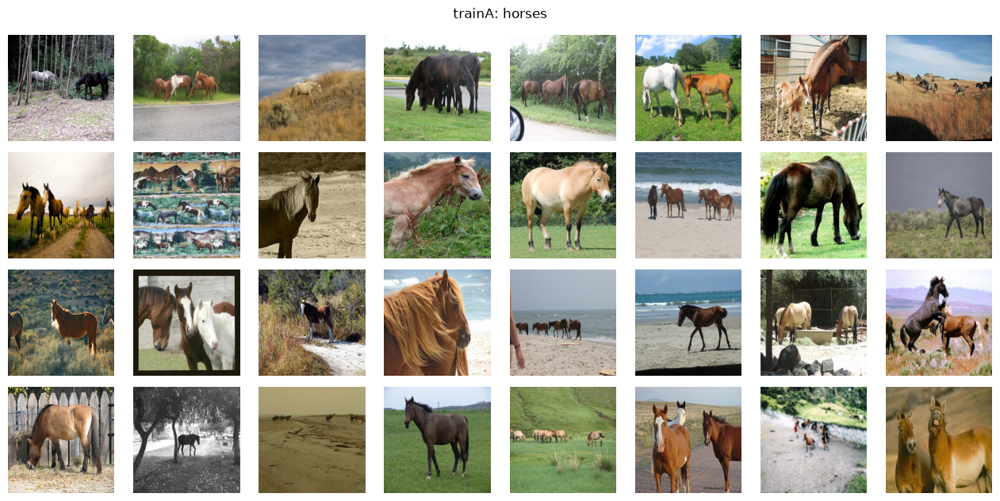

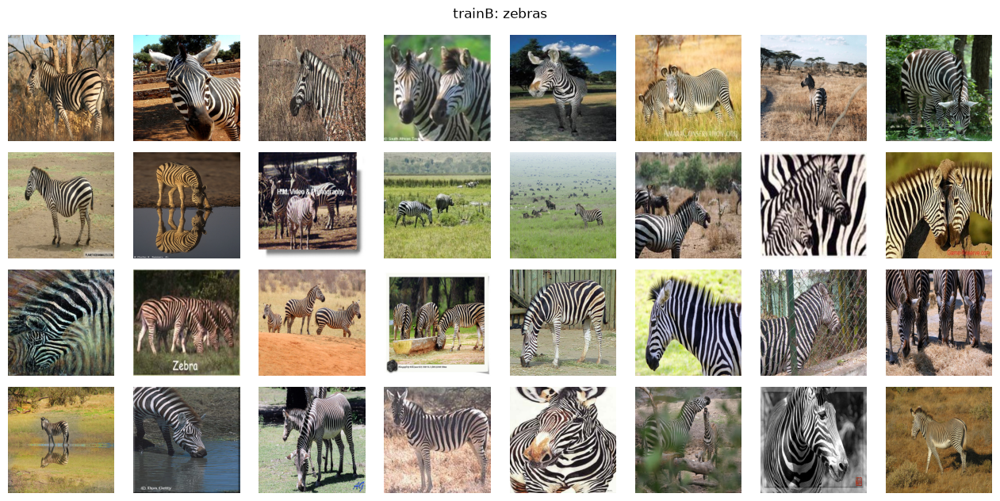

In [3]:
def load(path, size=None):
    im = Image.open(path).convert("RGB")
    if size:
        im = im.resize((size, size), Image.Resampling.BICUBIC)
    return np.asarray(im)

def show_grid(paths, title, rows=4, cols=8, size=None, labels=None):
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.6))
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < len(paths):
            ax.imshow(load(paths[i], size))
            if labels is not None:
                ax.set_title(labels[i], fontsize=7)
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show_grid(random.sample(files["trainA"], 32), "trainA: horses")
show_grid(random.sample(files["trainB"], 32), "trainB: zebras")

## 3. Colour and texture statistics

For every image we compute a few simple numbers:

| number | how it is computed | why it might matter |
|---|---|---|
| mean R, G, B | average of each colour channel | horses are brown, zebras black and white |
| brightness | average grey level | a sanity check: zebras average out to mid-grey, horses are often on bright grass or sky. If this alone separated them, a model could cheat |
| contrast | spread (std) of grey levels | stripes = lots of very dark next to very light |
| saturation | how colourful (from HSV) | zebras are nearly colourless |
| edge strength | average jump between neighbouring grey pixels | stripes = many sharp edges |

We also keep a 64×64 copy of every image for later sections (the first
diffusion model will train at 64×64).

In [4]:
def image_stats(rgb):
    grey = rgb.mean(axis=2)
    hsv = np.asarray(Image.fromarray(rgb).convert("HSV"))
    edges = (np.abs(np.diff(grey, axis=0)).mean() + np.abs(np.diff(grey, axis=1)).mean()) / 2
    return {
        "R": rgb[..., 0].mean(), "G": rgb[..., 1].mean(), "B": rgb[..., 2].mean(),
        "brightness": grey.mean(), "contrast": grey.std(),
        "saturation": hsv[..., 1].mean(), "edges": edges,
    }

stats, hist, small = {}, {}, {}
for s in SPLITS:
    stats[s], small[s] = [], []
    hist[s] = np.zeros((3, 256))               # pixel-value counts per channel
    for f in files[s]:
        rgb = load(f)
        stats[s].append(image_stats(rgb))
        for c in range(3):
            hist[s][c] += np.bincount(rgb[..., c].ravel(), minlength=256)
        small[s].append(np.asarray(Image.fromarray(rgb).resize((64, 64), Image.Resampling.BICUBIC)))
    small[s] = np.stack(small[s])
    print(f"{s}: {len(stats[s])} images done")

def column(split, key):
    return np.array([d[key] for d in stats[split]])

trainA: 1067 images done
trainB: 1334 images done
testA: 120 images done
testB: 140 images done


### 3a. Pixel-value histograms per colour channel

How often each brightness value (0 = black, 255 = white) appears, per channel,
over all training pixels.

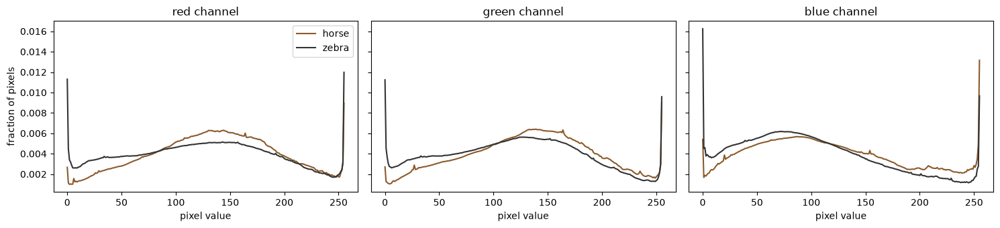

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), sharey=True)
for c, name in enumerate(["red", "green", "blue"]):
    for s in ["trainA", "trainB"]:
        d = DOMAIN[s[-1]]
        axes[c].plot(hist[s][c] / hist[s][c].sum(), color=COLOUR[d], label=d)
    axes[c].set_title(f"{name} channel")
    axes[c].set_xlabel("pixel value")
axes[0].set_ylabel("fraction of pixels")
axes[0].legend()
plt.tight_layout()
plt.show()


### 3b. Per-image brightness, contrast, saturation and edges

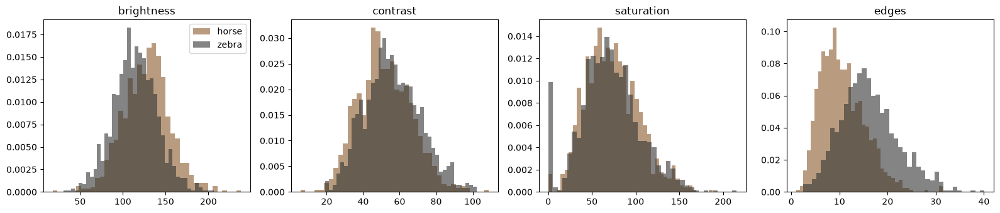

              horse mean  zebra mean
brightness         127.8       114.5
contrast            51.8        56.3
saturation          72.9        70.8
edges               10.6        16.1


In [6]:
keys = ["brightness", "contrast", "saturation", "edges"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, k in zip(axes, keys):
    for s in ["trainA", "trainB"]:
        d = DOMAIN[s[-1]]
        ax.hist(column(s, k), bins=40, alpha=0.6, color=COLOUR[d], label=d, density=True)
    ax.set_title(k)
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"{'':12} {'horse mean':>11} {'zebra mean':>11}")
for k in keys:
    print(f"{k:12} {column('trainA', k).mean():11.1f} {column('trainB', k).mean():11.1f}")

**Hypothesis to test:** a model will first learn the *easy* signal (overall
colour, contrast, edge density) before it learns what a zebra actually *is*.
If that is true, early or weak models will turn horse photos grey and stripy
**everywhere**, including the grass and sky, not only on the animal.


## 4. How far do simple numbers get?

A deliberately dumb classifier. For each single number from section 3, find the
best cut-off on the **training** images ("above X → zebra"), then check its
accuracy on the **test** images. Then combine all seven numbers using
"nearest average": an image is labelled with whichever class average its
numbers are closer to.

If these reach high accuracy, telling horses from zebras is "easy", and a
realism score like a horse-vs-zebra classifier can be fooled by colour alone.

In [7]:
FEATURES = ["R", "G", "B", "brightness", "contrast", "saturation", "edges"]

def features(split):
    return np.stack([column(split, k) for k in FEATURES], axis=1)

X_train = np.concatenate([features("trainA"), features("trainB")])
y_train = np.array([0] * len(stats["trainA"]) + [1] * len(stats["trainB"]))   # 1 = zebra
X_test = np.concatenate([features("testA"), features("testB")])
y_test = np.array([0] * len(stats["testA"]) + [1] * len(stats["testB"]))

def best_threshold(x, y):
    # Try every cut-off, in both directions, and keep the most accurate one.
    best = (0, None, None)
    for cut in np.unique(x):
        for sign in (1, -1):
            acc = ((sign * x > sign * cut) == y).mean()
            if acc > best[0]:
                best = (acc, cut, sign)
    return best

print(f"{'feature':12} {'train acc':>9} {'test acc':>9}   rule")
for i, k in enumerate(FEATURES):
    acc, cut, sign = best_threshold(X_train[:, i], y_train)
    test_acc = ((sign * X_test[:, i] > sign * cut) == y_test).mean()
    rule = f"zebra if {k} {'>' if sign == 1 else '<'} {cut:.1f}"
    print(f"{k:12} {acc:9.1%} {test_acc:9.1%}   {rule}")

# Nearest average, using all features. Standardise first so no feature dominates by scale.
mu, sd = X_train.mean(0), X_train.std(0)
Z_train, Z_test = (X_train - mu) / sd, (X_test - mu) / sd
centroids = np.stack([Z_train[y_train == c].mean(0) for c in (0, 1)])
pred = np.argmin(((Z_test[:, None, :] - centroids[None]) ** 2).sum(-1), axis=1)
print(f"\nall {len(FEATURES)} features, nearest average: test accuracy {(pred == y_test).mean():.1%}")

feature      train acc  test acc   rule
R                59.1%     58.1%   zebra if R < 135.7
G                62.1%     63.5%   zebra if G < 135.6
B                63.4%     65.4%   zebra if B < 124.8
brightness       62.5%     63.5%   zebra if brightness < 128.1
contrast         57.9%     58.5%   zebra if contrast > 49.1
saturation       55.5%     54.2%   zebra if saturation < 188.1
edges            71.1%     72.3%   zebra if edges > 12.4

all 7 features, nearest average: test accuracy 70.0%


## 5. Better hand-made features

Section 4 mostly measured colour. These numbers aim at what actually makes a
zebra a zebra. All of them are computed on a 128×128 grey (or HSV) copy.

| feature | what it measures | why it should help |
|---|---|---|
| black & white | share of pixels that are colourless *and* very dark or very light | stripes are black and white; horse coats are brown |
| fine detail | share of the image's energy at high spatial frequency (Fourier transform) | stripes repeat every few pixels, which is high frequency |
| aligned edges | how much the edges in each neighbourhood point the same way (structure tensor "coherence") | stripes are many *parallel* edges; grass and fur edges point every which way |
| green | share of colourful pixels that are green | background: horses in green fields, zebras on dry savanna? |

Plus two classic "texture fingerprints" from computer vision before deep learning:
* **HOG** (histogram of oriented gradients, 2005): cut the image into 16×16
  cells and, in each, count how much edge there is in each of 9 directions.
  1,764 numbers per image.
* **LBP** (local binary patterns): compare each pixel with its 8 neighbours,
  giving an 8-bit "brighter / darker" code. The histogram of codes describes the
  texture. 10 numbers per image.

HOG and LBP are too many numbers for a single cut-off, so we fit a **logistic
regression**: a weighted sum of the numbers, squashed to a 0–1 "zebra
probability". It is a neural network with no hidden layer, written here by hand.

In [8]:
from skimage.feature import hog, local_binary_pattern, structure_tensor, structure_tensor_eigenvalues

def grey128(rgb):
    return np.asarray(Image.fromarray(rgb).convert("L").resize((128, 128), Image.Resampling.BICUBIC), dtype=float) / 255

def coherence_map(g):
    # Structure tensor: per pixel, the 2 eigenvalues say how strong the edges are
    # along the main direction (l1) and across it (l2). Equal = no main direction.
    l1, l2 = structure_tensor_eigenvalues(structure_tensor(g, sigma=2, order="rc"))
    return l1, l2

def spectrum(g):
    return np.abs(np.fft.fftshift(np.fft.fft2(g - g.mean()))) ** 2

YY, XX = np.indices((128, 128)) - 64
RADIUS = np.hypot(YY, XX)                     # distance from the centre = spatial frequency

def better_stats(rgb):
    hsv = np.asarray(Image.fromarray(rgb).convert("HSV"), dtype=float) / 255
    hue, sat, val = hsv[..., 0] * 360, hsv[..., 1], hsv[..., 2]
    g = grey128(rgb)
    l1, l2 = coherence_map(g)
    F = spectrum(g)
    colourful = sat > 0.2
    return {
        "black_white": ((sat < 0.15) & ((val < 0.25) | (val > 0.75))).mean(),
        "fine_detail": F[RADIUS > 16].sum() / F.sum(),
        "aligned_edges": (l1 - l2).sum() / ((l1 + l2).sum() + 1e-8),
        "green": ((hue > 70) & (hue < 170) & colourful).mean(),
    }

def descriptors(rgb):
    g = grey128(rgb)
    h = hog(g, orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))
    codes = local_binary_pattern((g * 255).astype(np.uint8), P=8, R=1, method="uniform")
    return h, np.bincount(codes.astype(int).ravel(), minlength=10) / codes.size

better, hogs, lbps = {}, {}, {}
for s in SPLITS:
    better[s], hogs[s], lbps[s] = [], [], []
    for f in files[s]:
        rgb = load(f)
        better[s].append(better_stats(rgb))
        h, l = descriptors(rgb)
        hogs[s].append(h); lbps[s].append(l)
    hogs[s], lbps[s] = np.stack(hogs[s]), np.stack(lbps[s])
    print(f"{s}: done")

NEW = ["black_white", "fine_detail", "aligned_edges", "green"]
def bcol(split, key):
    return np.array([d[key] for d in better[split]])

trainA: done
trainB: done
testA: done
testB: done


### 5a. What each feature "sees"

Two horses and two zebras. Columns: the photo; **edge strength**; **aligned
edges** (bright = edges in this patch all point the same way); the **HOG**
picture (each cell drawn as little lines in its dominant edge directions); the
**Fourier spectrum** (centre = coarse shapes, edges = fine detail; the ring
marks the "fine detail" cut-off).

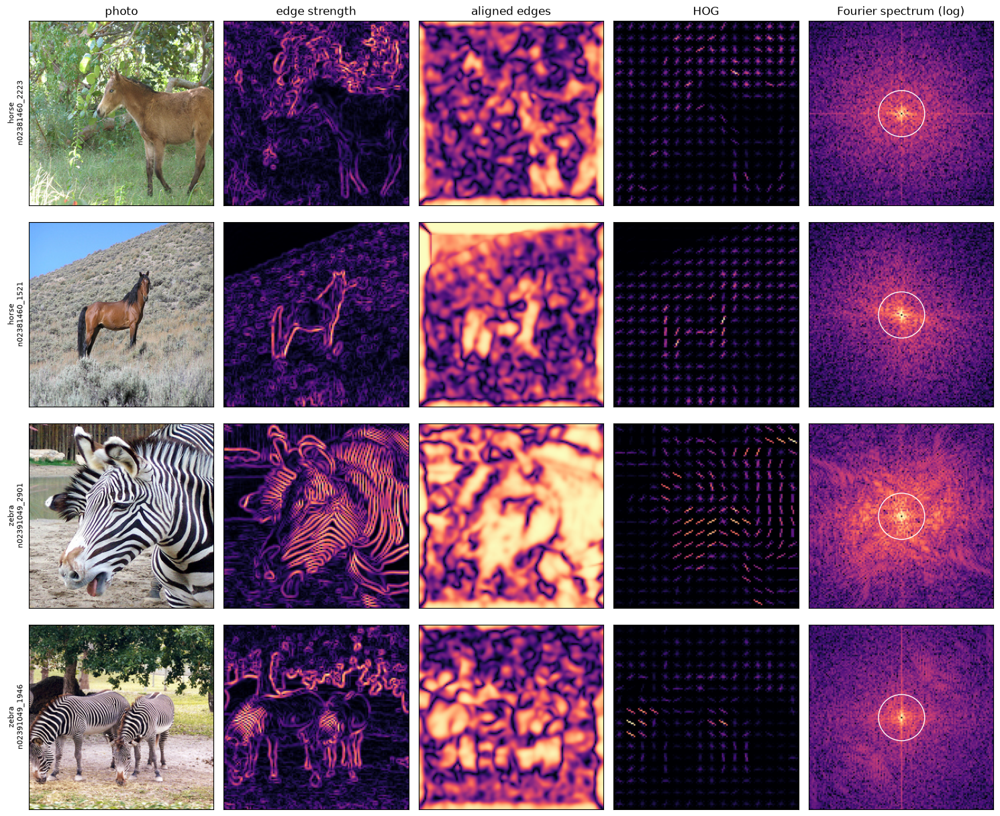

In [9]:
from matplotlib.patches import Circle
from skimage.filters import sobel

vis_rng = random.Random(1)        # its own generator, so later sections still pick the same images
examples = [("trainA", f) for f in vis_rng.sample(files["trainA"], 2)] + [("trainB", f) for f in vis_rng.sample(files["trainB"], 2)]
titles = ["photo", "edge strength", "aligned edges", "HOG", "Fourier spectrum (log)"]
fig, axes = plt.subplots(len(examples), 5, figsize=(15, 3.1 * len(examples)))
for r, (s, f) in enumerate(examples):
    rgb = load(f)
    g = grey128(rgb)
    l1, l2 = coherence_map(g)
    _, hog_img = hog(g, orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2), visualize=True)
    panels = [rgb, sobel(g), (l1 - l2) / (l1 + l2 + 1e-8), hog_img, np.log1p(spectrum(g))]
    for c, (ax, im) in enumerate(zip(axes[r], panels)):
        ax.imshow(im, cmap=None if c == 0 else "magma")
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(titles[c])
    axes[r, 4].add_patch(Circle((64, 64), 16, fill=False, color="white", lw=1))
    axes[r, 0].set_ylabel(f"{DOMAIN[s[-1]]}\n{f.stem}", fontsize=8)
plt.tight_layout()
plt.show()

### 5b. Do the new numbers separate the domains?

Same test as section 4: the best single cut-off per number, learnt on train and
checked on test.

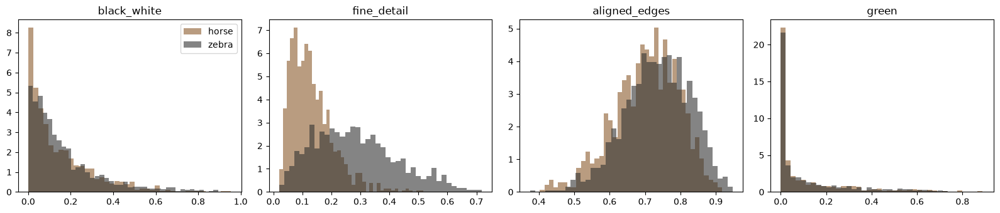

feature        train acc  test acc   rule
black_white        57.8%     59.6%   zebra if black_white > 0.032
fine_detail        75.9%     78.8%   zebra if fine_detail > 0.191
aligned_edges      57.9%     57.3%   zebra if aligned_edges > 0.655
green              55.6%     53.8%   zebra if green < 0.748


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, k in zip(axes, NEW):
    for s in ["trainA", "trainB"]:
        d = DOMAIN[s[-1]]
        ax.hist(bcol(s, k), bins=40, alpha=0.6, color=COLOUR[d], label=d, density=True)
    ax.set_title(k)
axes[0].legend()
plt.tight_layout()
plt.show()

print(f"{'feature':14} {'train acc':>9} {'test acc':>9}   rule")
for k in NEW:
    x_tr = np.concatenate([bcol("trainA", k), bcol("trainB", k)])
    x_te = np.concatenate([bcol("testA", k), bcol("testB", k)])
    acc, cut, sign = best_threshold(x_tr, y_train)
    test_acc = ((sign * x_te > sign * cut) == y_test).mean()
    print(f"{k:14} {acc:9.1%} {test_acc:9.1%}   zebra if {k} {'>' if sign == 1 else '<'} {cut:.3f}")

### 5c. Combine everything with a logistic regression

Each row adds more numbers. The model is the same every time: standardise the
numbers, then learn one weight per number (plus a bias) by gradient descent on
the training images. A small weight penalty (L2) stops it memorising the
1,764 HOG numbers.

In [11]:
def fit_logreg(X, y, l2=1e-2, steps=3000, lr=0.5):
    w, b = np.zeros(X.shape[1]), 0.0
    for _ in range(steps):
        p = 1 / (1 + np.exp(-(X @ w + b)))           # predicted P(zebra)
        w -= lr * (X.T @ (p - y) / len(y) + l2 * w)    # gradient of the log-loss
        b -= lr * (p - y).mean()
    return w, b

def run(name, tr, te):
    mu, sd = tr.mean(0), tr.std(0) + 1e-8
    w, b = fit_logreg((tr - mu) / sd, y_train)
    acc = lambda X, y: (((X - mu) / sd @ w + b > 0) == y).mean()
    print(f"{name:34} {tr.shape[1]:6} {acc(tr, y_train):9.1%} {acc(te, y_test):9.1%}")

def stack(fn):
    return (np.concatenate([fn("trainA"), fn("trainB")]), np.concatenate([fn("testA"), fn("testB")]))

simple = stack(features)                                                   # the 7 from section 4
new4 = stack(lambda s: np.stack([bcol(s, k) for k in NEW], 1))
lbp = stack(lambda s: lbps[s])
hogv = stack(lambda s: hogs[s])

print(f"{'features':34} {'count':>6} {'train acc':>9} {'test acc':>9}")
run("section 4 (colour, contrast, edges)", *simple)
run("+ 4 new numbers", *(np.concatenate([a, b], 1) for a, b in zip(simple, new4)))
run("LBP texture histogram", *lbp)
run("HOG", *hogv)
run("everything", *(np.concatenate(parts, 1) for parts in zip(simple, new4, lbp, hogv)))
print(f"\nmajority-class baseline: {max(y_test.mean(), 1 - y_test.mean()):.1%}")

features                            count train acc  test acc
section 4 (colour, contrast, edges)      7     72.9%     75.8%
+ 4 new numbers                        11     80.9%     85.4%
LBP texture histogram                  10     76.1%     75.0%
HOG                                  1764     85.3%     72.3%
everything                           1785     93.6%     86.2%

majority-class baseline: 53.8%


## 6. Scene content: what is in each photo?

A pretrained **object detector** (Faster R-CNN, trained on the COCO dataset,
which has both "horse" and "zebra" classes) draws a box around each object it
recognises. From the boxes we get:
* how many animals are in each photo;
* how much of the frame the biggest one fills (close-up or wide shot);
* what else is in the photo (people, cars, ...);
* photos where the detector finds **no** animal, or the **wrong** one.

It runs on the **CPU**: on Apple's MPS (GPU) backend this model returns empty
or wrong boxes. That takes about 40 minutes for all 2,661 images on an M2 Pro.
The results are cached in `outputs/diffusion/scene_detections.json`
(gitignored), so later runs load in a second. Delete the file to recompute.

The detector is a model too and makes mistakes, especially with small or
overlapping animals, so treat the counts as rough.

In [12]:
import os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2, FasterRCNN_ResNet50_FPN_V2_Weights
from torchvision.transforms.functional import pil_to_tensor

CACHE = ROOT / "outputs" / "diffusion" / "scene_detections.json"
MIN_SCORE = 0.5            # keep boxes the detector is at least 50% sure about

if CACHE.exists():
    detections = json.loads(CACHE.read_text())
else:
    weights = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT       # downloads ~170 MB the first time
    names = weights.meta["categories"]
    # The model enlarges every image internally (default 800 px). 512 is ~2x faster and still finds small animals.
    model = fasterrcnn_resnet50_fpn_v2(weights=weights, min_size=512, max_size=512).eval()
    detections = {}
    with torch.inference_mode():
        for s in SPLITS:
            detections[s] = {}
            for i in range(0, len(files[s]), 8):
                batch = files[s][i : i + 8]
                imgs = [pil_to_tensor(Image.open(f).convert("RGB")).float() / 255 for f in batch]
                for f, out in zip(batch, model(imgs)):
                    keep = out["scores"] >= MIN_SCORE
                    detections[s][f.name] = [
                        {"label": names[l], "score": round(sc, 3), "box": [round(v, 1) for v in b]}
                        for l, sc, b in zip(out["labels"][keep].tolist(), out["scores"][keep].tolist(), out["boxes"][keep].tolist())
                    ]
                print(f"\r{s}: {min(i + 8, len(files[s]))}/{len(files[s])}", end="")
            print()
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    CACHE.write_text(json.dumps(detections))
print({s: len(d) for s, d in detections.items()})

trainA: 1067/1067
trainB: 1334/1334
testA: 120/120
testB: 140/140
{'trainA': 1067, 'trainB': 1334, 'testA': 120, 'testB': 140}


### 6a. Counts, framing and extra objects

"own animal" = horse in the A folders, zebra in the B folders. "Biggest" is the
share of the 256×256 frame covered by the largest own-animal box.

       split         none            1          2-3           4+     close-up         wide       person wrong animal
      trainA         2.0%        41.5%        35.1%        21.5%        18.1%        31.8%         7.1%         0.7%
      trainB         0.7%        52.1%        32.8%        14.3%        47.8%         9.2%         4.5%         1.8%
       testA         7.5%        32.5%        36.7%        23.3%        16.7%        35.0%        15.8%         0.0%
       testB         0.0%        62.9%        25.0%        12.1%        52.9%        10.0%         5.0%         1.4%

close-up = biggest animal covers > 50% of the frame; wide = < 10%


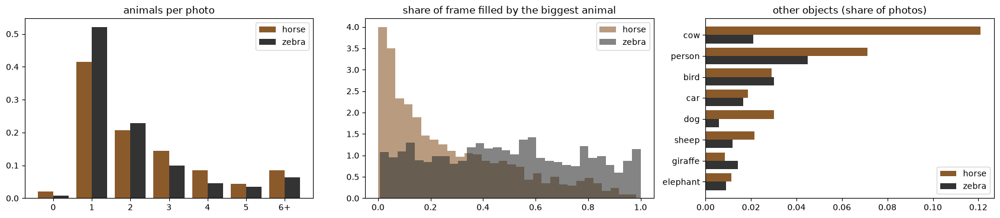

In [13]:
from collections import Counter

def summarise(split):
    animal = "horse" if split.endswith("A") else "zebra"
    other = "zebra" if animal == "horse" else "horse"
    rows = []
    for name, dets in detections[split].items():
        own = [d for d in dets if d["label"] == animal]
        areas = [(d["box"][2] - d["box"][0]) * (d["box"][3] - d["box"][1]) / 256**2 for d in own]
        rows.append({
            "name": name, "n": len(own), "biggest": max(areas, default=0.0),
            "person": any(d["label"] == "person" for d in dets),
            "wrong": any(d["label"] == other for d in dets),
            "others": {d["label"] for d in dets} - {animal, other},
        })
    return rows

scene = {s: summarise(s) for s in SPLITS}

hdr = ["split", "none", "1", "2-3", "4+", "close-up", "wide", "person", "wrong animal"]
print(" ".join(f"{h:>12}" for h in hdr))
for s in SPLITS:
    r = scene[s]
    n = np.array([x["n"] for x in r]); big = np.array([x["biggest"] for x in r])
    vals = [(n == 0).mean(), (n == 1).mean(), ((n >= 2) & (n <= 3)).mean(), (n >= 4).mean(),
            (big > 0.5).mean(), ((big > 0) & (big < 0.1)).mean(),
            np.mean([x["person"] for x in r]), np.mean([x["wrong"] for x in r])]
    print(f"{s:>12} " + " ".join(f"{v:12.1%}" for v in vals))
print("\nclose-up = biggest animal covers > 50% of the frame; wide = < 10%")

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
for s in ["trainA", "trainB"]:
    d = DOMAIN[s[-1]]
    n = np.array([x["n"] for x in scene[s]])
    counts = np.bincount(np.minimum(n, 6), minlength=7) / len(n)
    off = -0.2 if d == "horse" else 0.2
    axes[0].bar(np.arange(7) + off, counts, width=0.4, color=COLOUR[d], label=d)
    axes[1].hist([x["biggest"] for x in scene[s] if x["n"]], bins=30, alpha=0.6, color=COLOUR[d], label=d, density=True)
axes[0].set_xticks(range(7), ["0", "1", "2", "3", "4", "5", "6+"])
axes[0].set_title("animals per photo"); axes[0].legend()
axes[1].set_title("share of frame filled by the biggest animal"); axes[1].legend()

top = Counter()
for s in ["trainA", "trainB"]:
    top.update(o for x in scene[s] for o in x["others"] | ({"person"} if x["person"] else set()))
labels = [k for k, _ in top.most_common(8)]
for s, off in [("trainA", -0.2), ("trainB", 0.2)]:
    share = [np.mean([k in x["others"] or (k == "person" and x["person"]) for x in scene[s]]) for k in labels]
    axes[2].barh(np.arange(len(labels)) + off, share, height=0.4, color=COLOUR[DOMAIN[s[-1]]], label=DOMAIN[s[-1]])
axes[2].set_yticks(range(len(labels)), labels); axes[2].invert_yaxis()
axes[2].set_title("other objects (share of photos)"); axes[2].legend()
plt.tight_layout()
plt.show()

### 6b. Look at the odd ones

Boxes: orange = horse, blue = zebra, grey = anything else.

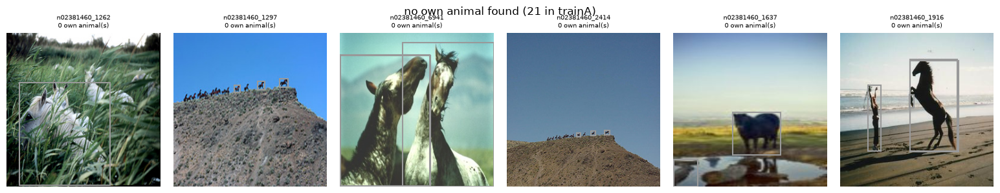

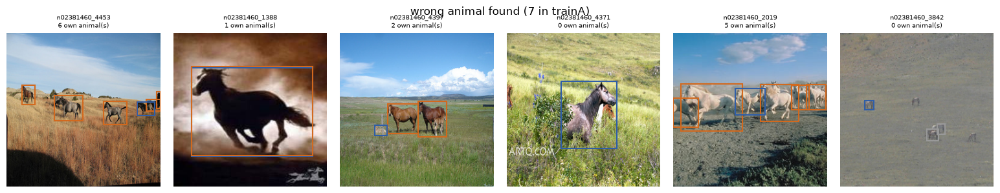

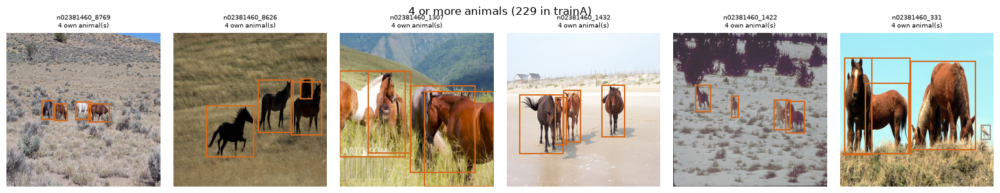

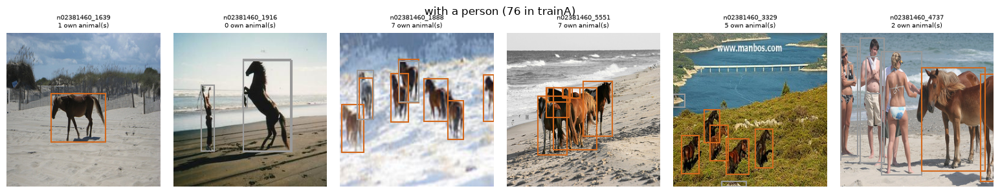

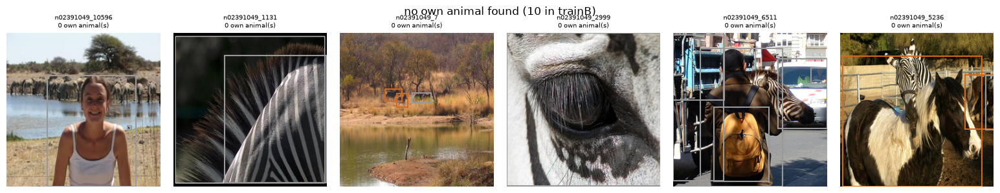

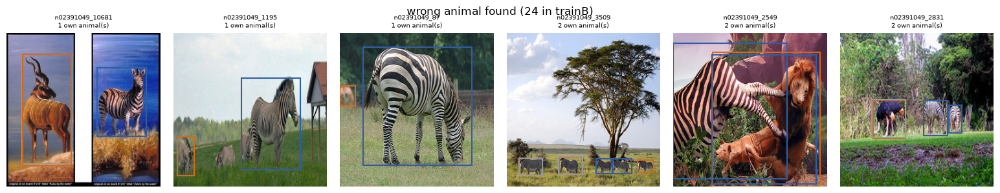

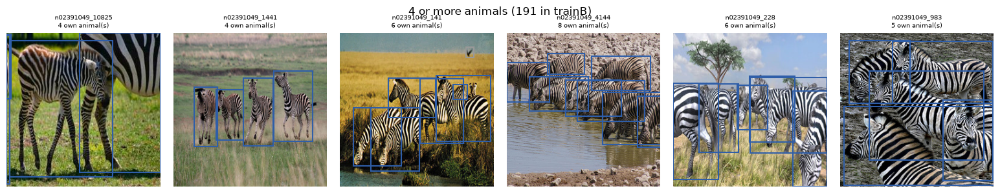

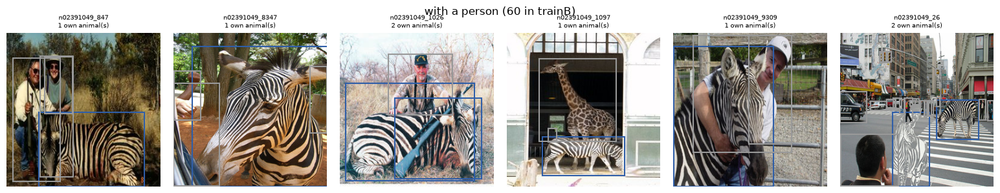

In [14]:
from matplotlib.patches import Rectangle

BOX = {"horse": "#d2691e", "zebra": "#2f5ea8"}

def show_boxes(split, rows_, title, k=6):
    if not rows_:
        print(f"{title}: none"); return
    pick = random.Random(2).sample(rows_, min(k, len(rows_)))
    fig, axes = plt.subplots(1, len(pick), figsize=(2.6 * len(pick), 3), squeeze=False)
    for ax, x in zip(axes[0], pick):
        ax.imshow(load(DATA / split / x["name"]))
        for d in detections[split][x["name"]]:
            x0, y0, x1, y1 = d["box"]
            ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, lw=1.5, color=BOX.get(d["label"], "#999999")))
        ax.set_title(f'{x["name"][:-4]}\n{x["n"]} own animal(s)', fontsize=7)
        ax.axis("off")
    fig.suptitle(f"{title} ({len(rows_)} in {split})")
    plt.tight_layout()
    plt.show()

for s in ["trainA", "trainB"]:
    show_boxes(s, [x for x in scene[s] if x["n"] == 0], "no own animal found")
    show_boxes(s, [x for x in scene[s] if x["wrong"]], "wrong animal found")
    show_boxes(s, [x for x in scene[s] if x["n"] >= 4], "4 or more animals")
    show_boxes(s, [x for x in scene[s] if x["person"]], "with a person")

**Your notes** (are the "no animal" photos detector mistakes or real oddities?
how different is the framing of horses vs zebras? riders and saddles are a
"horse" thing: what should a horse-to-zebra model do with the rider?):

## 7. What survives at 64×64?

The first diffusion model will work at 64×64 (16× fewer pixels) because that is
much cheaper. Do the stripes survive the shrink? Top row: the original 256×256.
Bottom row: the same image at 64×64, displayed at the same size.

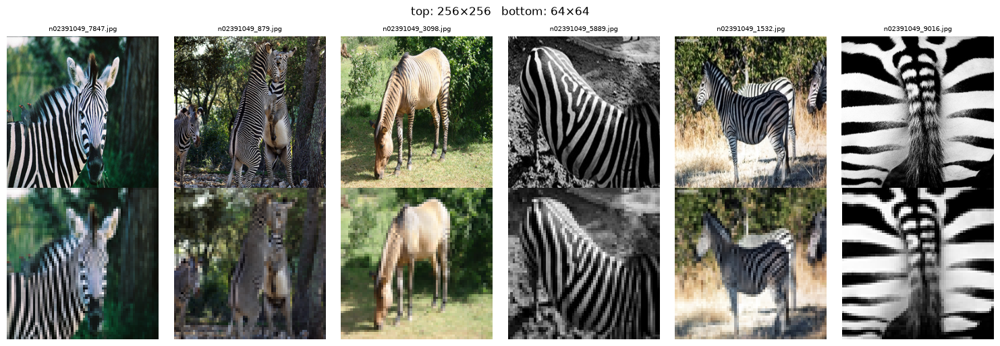

In [15]:
picks = random.sample(range(len(files["trainB"])), 6)
fig, axes = plt.subplots(2, 6, figsize=(15, 5.2))
for j, i in enumerate(picks):
    axes[0, j].imshow(load(files["trainB"][i]))
    axes[1, j].imshow(small["trainB"][i], interpolation="nearest")
    axes[0, j].set_title(files["trainB"][i].name, fontsize=7)
for ax in axes.flat:
    ax.axis("off")
axes[0, 0].set_ylabel("256")
fig.suptitle("top: 256×256   bottom: 64×64")
plt.tight_layout()
plt.show()

## 8. Near-duplicate images

Duplicates matter for two reasons:
* A test image that is (almost) also in the training set makes test scores look
  better than they are.
* Later we check whether our model *memorised* training images. Duplicates in
  the training data make memorisation more likely.

A quick, rough check: shrink every image to a 16×16 grey thumbnail, then use
**cosine similarity** (1.0 = identical pattern) to find each image's closest
match. This only catches near-identical photos, not "similar scenes". The 0.97
cut-off is a judgement call: look at the pairs and decide.

trainA vs trainA: 12 pairs above 0.97


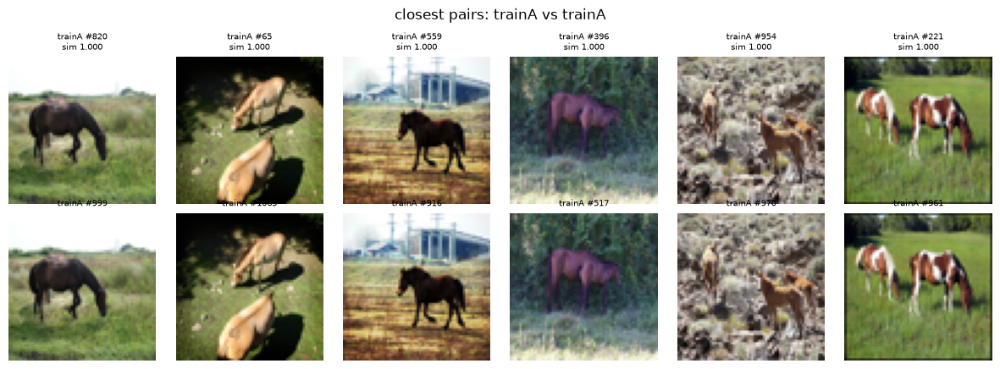

trainB vs trainB: 24 pairs above 0.97


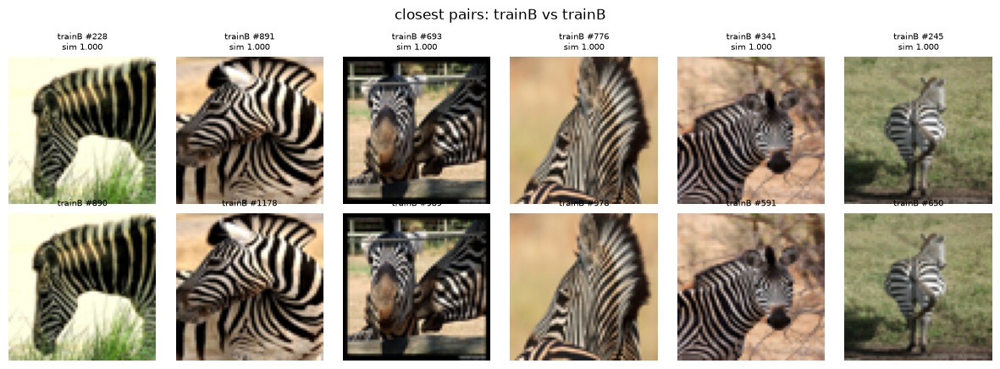

trainA vs testA: 1 pairs above 0.97


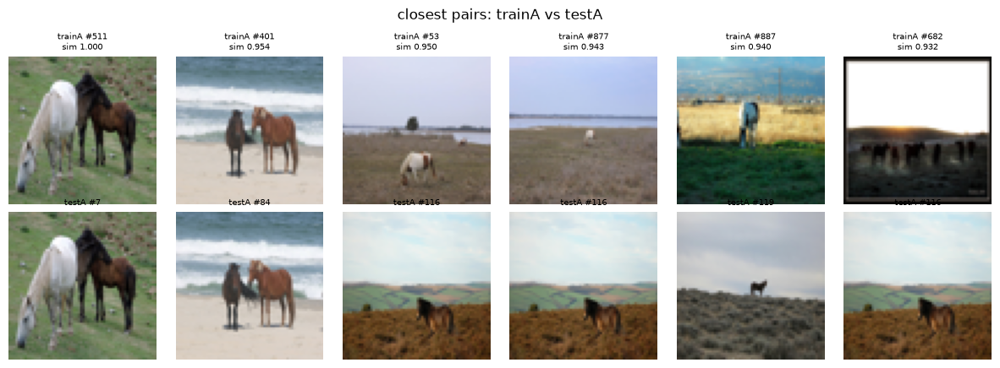

trainB vs testB: 1 pairs above 0.97


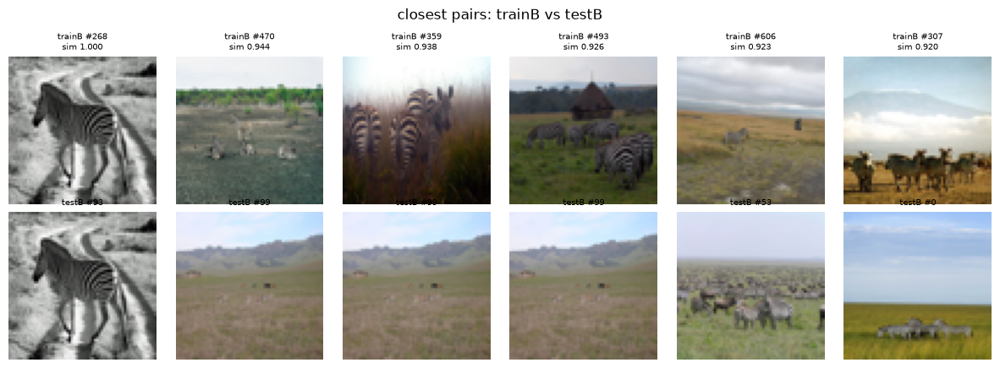

In [16]:
def thumbs(split):
    t = np.stack([np.asarray(Image.fromarray(im).convert("L").resize((16, 16))) for im in small[split]])
    t = t.reshape(len(t), -1).astype(float)
    t -= t.mean(1, keepdims=True)                       # ignore overall brightness
    return t / (np.linalg.norm(t, axis=1, keepdims=True) + 1e-8)

def closest_pairs(a, b, same_split):
    sim = thumbs(a) @ thumbs(b).T
    if same_split:
        sim[np.tril_indices_from(sim)] = -1             # don't match an image with itself, or count a pair twice
    best_j = sim.argmax(1)
    best = sim[np.arange(len(sim)), best_j]
    order = np.argsort(-best)
    return [(i, best_j[i], best[i]) for i in order]

THRESHOLD = 0.97
for a, b in [("trainA", "trainA"), ("trainB", "trainB"), ("trainA", "testA"), ("trainB", "testB")]:
    pairs = closest_pairs(a, b, same_split=(a == b))
    n = sum(s > THRESHOLD for _, _, s in pairs)
    print(f"{a} vs {b}: {n} pairs above {THRESHOLD}")
    top = pairs[:6]
    fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
    for j, (i, k, s) in enumerate(top):
        axes[0, j].imshow(small[a][i]); axes[0, j].set_title(f"{a} #{i}\nsim {s:.3f}", fontsize=7)
        axes[1, j].imshow(small[b][k]); axes[1, j].set_title(f"{b} #{k}", fontsize=7)
    for ax in axes.flat:
        ax.axis("off")
    fig.suptitle(f"closest pairs: {a} vs {b}")
    plt.tight_layout()
    plt.show()

## 9. Choose the 10 fixed evaluation horses

Every method (CycleGAN, Stable Diffusion SDEdit, our DDPM) will be shown on
**exactly these 10 test horses**, so they can be compared side by side.

Below is a random pick (seeded, so it is the same every run). Aim for variety:
close-up and far away, one horse and several, different backgrounds, at least
one awkward case. If you want to swap one, replace its filename in `chosen`
and re-run this cell.

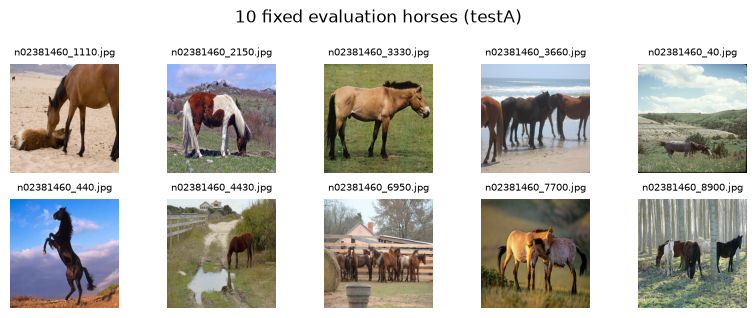

saved diffusion/eval/fixed_eval_set.json


In [17]:
rng = random.Random(SEED)
chosen = sorted(rng.sample([f.name for f in files["testA"]], 10))
# chosen[3] = "n02381460_XXXX.jpg"   # <- swap by hand if you want more variety

show_grid([DATA / "testA" / name for name in chosen], "10 fixed evaluation horses (testA)",
          rows=2, cols=5, labels=chosen)

out = ROOT / "diffusion" / "eval" / "fixed_eval_set.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps({"split": "testA", "seed": SEED, "images": chosen}, indent=2) + "\n")
print("saved", out.relative_to(ROOT))